# CREMA-D — figuras científicas V3 a partir dos artefatos canônicos

Este notebook **não treina novamente** os modelos e não produz ilustrações fictícias. Ele reconstrói as figuras do artigo diretamente da execução canônica `20260809_223452_c0613d3c`:

- quadros reais dos vídeos CREMA-D armazenados no Google Drive;
- cache real de 7.441 sequências, com 100 passos e 155 marcos faciais;
- matrizes reais de posição e diferenças temporais de primeira, segunda e terceira ordens;
- checkpoint executado do EmoT para obter projeções, matrizes de atenção e probabilidades;
- Attention Rollout, Integrated Gradients, validação Captum e oclusão regional já calculados.

As saídas são geradas em português e inglês, em PNG de alta resolução e PDF. Os nomes dos quatro PNGs coincidem com os arquivos dos projetos Overleaf V2, facilitando a substituição posterior. Cada etapa deixa um marcador de conclusão no Drive; se o runtime cair, execute novamente e as figuras já concluídas serão preservadas.

**Runtime:** CPU é suficiente. A maior parte do tempo é leitura do Drive e descompressão dos tensores; uma GPU não é necessária para a inferência de uma única sequência.


In [1]:
# Dependências leves. PyTorch, NumPy, pandas e Matplotlib já vêm no Colab.
%pip install -q --upgrade opencv-python-headless seaborn


In [2]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import shutil
import time
from pathlib import Path

import cv2
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.gridspec import GridSpec
from IPython.display import display

try:
    from google.colab import drive, files
except ImportError as exc:
    raise RuntimeError("Execute este notebook no Google Colab.") from exc

drive.mount("/content/drive", force_remount=False)

# ---------------------------------------------------------------------------
# Configuração: normalmente não é necessário alterar nada abaixo.
# ---------------------------------------------------------------------------
RUN_ID = "20260809_223452_c0613d3c"
BASE_DIR = Path("/content/drive/MyDrive/cremad_fairness_xai")
RUN_DIR = BASE_DIR / "runs" / RUN_ID
OUTPUT_ROOT = BASE_DIR / "paper_figures_v3" / RUN_ID
LOCAL_CACHE_DIR = Path("/content/cremad_figures_v3_cache")

COPY_HEAVY_FILES_TO_LOCAL = True  # acelera leituras repetidas; a cópia é retomável
FORCE_FIGURES = set()             # ex.: {"experimental", "xai"}
DOWNLOAD_FINAL_ZIP = False        # True baixa o ZIP ao final
SEED = 42

PT_DIR = OUTPUT_ROOT / "overleaf_ptbr" / "figures"
EN_DIR = OUTPUT_ROOT / "overleaf_en" / "figures"
STATE_DIR = OUTPUT_ROOT / "state"
for directory in (PT_DIR, EN_DIR, STATE_DIR, LOCAL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

PATHS = {
    "landmarks": BASE_DIR / "cache" / "cremad_landmarks_T100_semantic.npz",
    "manifest": RUN_DIR / "outputs" / "tables" / "manifest_valid_with_splits.csv",
    "visual_manifest": RUN_DIR / "outputs" / "tables" / "visual_sample_manifest.csv",
    "cv_fold_metrics": RUN_DIR / "outputs" / "tables" / "cv_fold_metrics.csv",
    "cv_summary": RUN_DIR / "outputs" / "tables" / "cv_summary_mean_std.csv",
    "attention": RUN_DIR / "outputs" / "xai" / "xai_attention_rollout_emot.npz",
    "xai_manifest": RUN_DIR / "outputs" / "xai" / "xai_sample_manifest.csv",
    "ig": RUN_DIR / "outputs" / "xai" / "xai_integrated_gradients_emot.npz",
    "captum_csv": RUN_DIR / "outputs" / "xai" / "xai_captum_integrated_gradients_validation.csv",
    "occlusion_csv": RUN_DIR / "outputs" / "xai" / "xai_region_occlusion_by_race.csv",
    "checkpoint": RUN_DIR / "outputs" / "models" / "best_EmoT.pt",
    "videos": BASE_DIR / "raw" / "videos_flv",
}

missing = [f"{name}: {path}" for name, path in PATHS.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Artefatos canônicos ausentes no Drive:\n- " + "\n- ".join(missing)
    )

print(f"Run canônico: {RUN_ID}")
print(f"Saída persistente: {OUTPUT_ROOT}")
display(pd.DataFrame({"artefato": PATHS.keys(), "caminho": map(str, PATHS.values())}))


Mounted at /content/drive
Run canônico: 20260809_223452_c0613d3c
Saída persistente: /content/drive/MyDrive/cremad_fairness_xai/paper_figures_v3/20260809_223452_c0613d3c


,artefato,caminho
0,landmarks,/content/drive/MyDrive/cremad_fairness_xai/cac...
1,manifest,/content/drive/MyDrive/cremad_fairness_xai/run...
2,visual_manifest,/content/drive/MyDrive/cremad_fairness_xai/run...
3,cv_fold_metrics,/content/drive/MyDrive/cremad_fairness_xai/run...
4,cv_summary,/content/drive/MyDrive/cremad_fairness_xai/run...
5,attention,/content/drive/MyDrive/cremad_fairness_xai/run...
6,xai_manifest,/content/drive/MyDrive/cremad_fairness_xai/run...
7,ig,/content/drive/MyDrive/cremad_fairness_xai/run...
8,captum_csv,/content/drive/MyDrive/cremad_fairness_xai/run...
9,occlusion_csv,/content/drive/MyDrive/cremad_fairness_xai/run...


In [3]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while chunk := handle.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


def localize(name: str) -> Path:
    # Copia arquivos pesados para o disco efêmero, retomando por tamanho.
    source = PATHS[name]
    if not COPY_HEAVY_FILES_TO_LOCAL or source.is_dir():
        return source
    target = LOCAL_CACHE_DIR / source.name
    if target.exists() and target.stat().st_size == source.stat().st_size:
        print(f"[cache] reutilizado: {target.name}")
        return target
    temporary = target.with_suffix(target.suffix + ".partial")
    if temporary.exists():
        temporary.unlink()
    print(f"[cache] copiando {source.name} ({source.stat().st_size / 2**20:.1f} MiB) ...")
    shutil.copy2(source, temporary)
    os.replace(temporary, target)
    return target


LOCAL = {
    name: localize(name) if name in {"landmarks", "attention", "ig", "checkpoint"} else path
    for name, path in PATHS.items()
}

input_audit = []
for name, path in PATHS.items():
    if path.is_file():
        input_audit.append(
            {
                "name": name,
                "bytes": path.stat().st_size,
                "sha256": sha256_file(path),
                "path": str(path),
            }
        )
pd.DataFrame(input_audit).to_csv(OUTPUT_ROOT / "input_artifact_audit.csv", index=False)
print("Auditoria dos artefatos de entrada gravada.")


[cache] copiando cremad_landmarks_T100_semantic.npz (615.1 MiB) ...
[cache] copiando xai_attention_rollout_emot.npz (0.4 MiB) ...
[cache] copiando xai_integrated_gradients_emot.npz (262.4 MiB) ...
[cache] copiando best_EmoT.pt (11.4 MiB) ...
Auditoria dos artefatos de entrada gravada.


In [4]:
# Carregamento dos dados canônicos.
with np.load(LOCAL["landmarks"], allow_pickle=False) as data:
    X_BASE = data["X_base"].astype(np.float32)
    Y = data["y"].astype(int)
    FILE_STEMS = data["file_stems"].astype(str)
    SELECTED_LANDMARK_IDS = data["selected_landmark_ids"].astype(int)

MANIFEST = pd.read_csv(PATHS["manifest"])
VISUAL_MANIFEST = pd.read_csv(PATHS["visual_manifest"])
CV_FOLDS = pd.read_csv(PATHS["cv_fold_metrics"])
CV_SUMMARY = pd.read_csv(PATHS["cv_summary"])
XAI_MANIFEST = pd.read_csv(PATHS["xai_manifest"])
CAPTUM = pd.read_csv(PATHS["captum_csv"])
OCCLUSION = pd.read_csv(PATHS["occlusion_csv"])

with np.load(LOCAL["attention"], allow_pickle=False) as data:
    ATTENTION_CURVES = data["attention_curves"].astype(np.float32)
    XAI_PREDS = data["xai_preds"].astype(int)

with np.load(LOCAL["ig"], allow_pickle=False) as data:
    IG_ATTR = data["ig_attr"].astype(np.float32)
    IG_INDICES = data["ig_indices"].astype(int)

assert X_BASE.shape == (7441, 100, 310), X_BASE.shape
assert len(FILE_STEMS) == len(X_BASE)
assert len(SELECTED_LANDMARK_IDS) == 155
assert ATTENTION_CURVES.shape[1] == 100
assert IG_ATTR.shape[1:] == (100, 1240), IG_ATTR.shape
assert len(IG_INDICES) == len(IG_ATTR)
assert len(XAI_MANIFEST) == len(ATTENTION_CURVES)

STEM_TO_INDEX = {stem: index for index, stem in enumerate(FILE_STEMS)}
CLASS_NAMES_EN = ["angry", "disgust", "fear", "happy", "neutral", "sad"]
CLASS_NAMES_PT = ["raiva", "nojo", "medo", "alegria", "neutra", "tristeza"]
FEATURE_BLOCKS = ["pos", "d1", "d2", "d3"]

print("Shapes canônicos validados:")
display(
    pd.DataFrame(
        [
            ("landmarks", str(X_BASE.shape)),
            ("attention rollout", str(ATTENTION_CURVES.shape)),
            ("integrated gradients", str(IG_ATTR.shape)),
            ("amostras Captum", str(len(CAPTUM))),
        ],
        columns=["artefato", "shape/n"],
    )
)


Shapes canônicos validados:


,artefato,shape/n
0,landmarks,"(7441, 100, 310)"
1,attention rollout,"(1142, 100)"
2,integrated gradients,"(600, 100, 1240)"
3,amostras Captum,64


In [5]:
# Definições exatas da execução e utilitários visuais.
REGION_IDS = {
    "lips": {0,13,14,17,37,39,40,61,78,80,81,82,84,87,88,91,95,146,178,181,185,191,267,269,270,291,308,310,311,312,314,317,318,321,324,375,402,405,409,415},
    "left_eye": {249,263,362,373,374,380,381,382,384,385,386,387,388,390,398,466},
    "right_eye": {7,33,133,144,145,153,154,155,157,158,159,160,161,163,173,246},
    "left_eyebrow": {276,282,283,285,293,295,296,300,334,336},
    "right_eyebrow": {46,52,53,55,63,65,66,70,105,107},
    "nose": {1,2,4,5,45,48,64,94,97,98,115,168,195,197,219,220,235,240,275,278,290,305,326,327,344,439,440},
    "face_oval": {10,21,54,58,67,93,103,109,127,132,136,148,149,150,152,162,172,176,234,251,284,288,297,323,332,338,356,361,365,377,378,379,389,397,400,454},
}
ID_TO_POS = {int(lm_id): pos for pos, lm_id in enumerate(SELECTED_LANDMARK_IDS)}
REGION_POSITIONS = {
    region: np.array([ID_TO_POS[i] for i in ids if i in ID_TO_POS], dtype=int)
    for region, ids in REGION_IDS.items()
}

PALETTE = {
    "navy": "#132A4F",
    "blue": "#2F6BFF",
    "cyan": "#00A6A6",
    "orange": "#E76F51",
    "gold": "#E9C46A",
    "slate": "#5E6A7D",
    "light": "#F5F7FA",
}

mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 9.5,
        "axes.titlesize": 10.5,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
    }
)
sns.set_theme(style="ticks", context="paper", font="DejaVu Sans")


def compute_temporal_blocks(seq: np.ndarray) -> list[np.ndarray]:
    vel = np.zeros_like(seq)
    vel[1:] = seq[1:] - seq[:-1]
    acc = np.zeros_like(seq)
    acc[1:-1] = seq[2:] - 2 * seq[1:-1] + seq[:-2]
    d3 = np.zeros_like(seq)
    d3[2:-2] = seq[4:] - 2 * seq[3:-1] + 2 * seq[1:-3] - seq[:-4]
    return [seq, vel, acc, d3]


def block_magnitude(block: np.ndarray) -> np.ndarray:
    return np.linalg.norm(block.reshape(100, 155, 2), axis=-1)


def video_path(stem: str) -> Path:
    return PATHS["videos"] / f"{stem}.flv"


def read_video_frames(stem: str, normalized_positions: list[float]) -> list[np.ndarray]:
    path = video_path(stem)
    cap = cv2.VideoCapture(str(path))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if frame_count <= 0:
        cap.release()
        raise RuntimeError(f"Vídeo sem quadros: {path}")
    result = []
    for fraction in normalized_positions:
        index = int(round(np.clip(fraction, 0, 1) * (frame_count - 1)))
        cap.set(cv2.CAP_PROP_POS_FRAMES, index)
        ok, frame = cap.read()
        if not ok:
            cap.release()
            raise RuntimeError(f"Não foi possível ler o quadro {index} de {path}")
        result.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    return result


def choose_examples() -> pd.DataFrame:
    candidates = VISUAL_MANIFEST.copy()
    if "file_stem" not in candidates:
        candidates = MANIFEST.copy()
    candidates = candidates[candidates["file_stem"].astype(str).isin(STEM_TO_INDEX)]
    candidates = candidates[
        candidates["file_stem"].astype(str).map(lambda stem: video_path(stem).exists())
    ]
    rows = []
    if "Race" in candidates:
        for _, group in candidates.groupby("Race", dropna=False, sort=True):
            rows.append(group.sort_values("file_stem").iloc[0])
    if not rows:
        rows = [candidates.sort_values("file_stem").iloc[0]]
    return pd.DataFrame(rows).reset_index(drop=True).head(4)


EXAMPLES = choose_examples()
PRIMARY_STEM = str(EXAMPLES.iloc[0]["file_stem"])
PRIMARY_INDEX = STEM_TO_INDEX[PRIMARY_STEM]
PRIMARY_SEQ = X_BASE[PRIMARY_INDEX]


def panel_label(ax, letter: str):
    ax.text(
        -0.08,
        1.04,
        letter,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        color=PALETTE["navy"],
        va="bottom",
    )


def robust_limits(values: np.ndarray, symmetric: bool = False):
    finite = np.asarray(values)[np.isfinite(values)]
    if symmetric:
        limit = float(np.quantile(np.abs(finite), 0.995)) or 1.0
        return -limit, limit
    low, high = np.quantile(finite, [0.01, 0.995])
    if not high > low:
        high = low + 1.0
    return float(low), float(high)


FIGURE_RECORDS = []


def save_figure(fig, basename: str, language: str, source_note: str):
    target_dir = PT_DIR if language == "pt" else EN_DIR
    png_path = target_dir / basename
    pdf_path = target_dir / (Path(basename).stem + "_print.pdf")
    png_tmp = png_path.with_suffix(".partial.png")
    pdf_tmp = pdf_path.with_suffix(".partial.pdf")
    fig.savefig(png_tmp, dpi=450, bbox_inches="tight", pad_inches=0.04)
    fig.savefig(pdf_tmp, bbox_inches="tight", pad_inches=0.04)
    os.replace(png_tmp, png_path)
    os.replace(pdf_tmp, pdf_path)
    FIGURE_RECORDS.append(
        {
            "language": language,
            "file": str(png_path.relative_to(OUTPUT_ROOT)),
            "bytes": png_path.stat().st_size,
            "sha256": sha256_file(png_path),
            "run_id": RUN_ID,
            "source_note": source_note,
        }
    )
    plt.show()
    plt.close(fig)
    return png_path


def outputs_for(stage: str) -> list[Path]:
    names = {
        "experimental": "visao_experimental_comparativa_v2.png",
        "adaptation": "adaptacao_emot_corpo_face_v2.png",
        "architecture": "arquitetura_emot_facial_v2.png",
        "xai": "xai_gradientes_integrados_v2.png",
    }
    return [PT_DIR / names[stage], EN_DIR / names[stage]]


def should_run(stage: str) -> bool:
    return stage in FORCE_FIGURES or not all(path.exists() and path.stat().st_size > 10_000 for path in outputs_for(stage))


def mark_stage(stage: str, metadata: dict):
    payload = {"stage": stage, "status": "completed", "run_id": RUN_ID, "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S"), **metadata}
    target = STATE_DIR / f"{stage}.json"
    temporary = target.with_suffix(".partial.json")
    temporary.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")
    os.replace(temporary, target)


display(EXAMPLES[[column for column in ["file_stem", "label_name", "Race", "Sex", "age_bin"] if column in EXAMPLES]])
print(f"Amostra principal reprodutível: {PRIMARY_STEM}")


,file_stem,label_name,Race,Sex,age_bin
0,1070_MTI_FEA_XX,fear,African American,Male,20-29
1,1072_TAI_FEA_XX,fear,Asian,Female,30-39
2,1065_TSI_SAD_XX,sad,Caucasian,Male,30-39
3,1047_ITH_FEA_XX,fear,Unknown,Female,20-29


Amostra principal reprodutível: 1070_MTI_FEA_XX


## Figura 1 — evidência experimental com entrada controlada

O painel reúne quadros reais, densidade global de landmarks, quatro matrizes cinemáticas de uma sequência real e os cinco resultados externos de cada modelo. As matrizes são mostradas como grandezas bidimensionais por marco, sem conversão para unidades físicas.


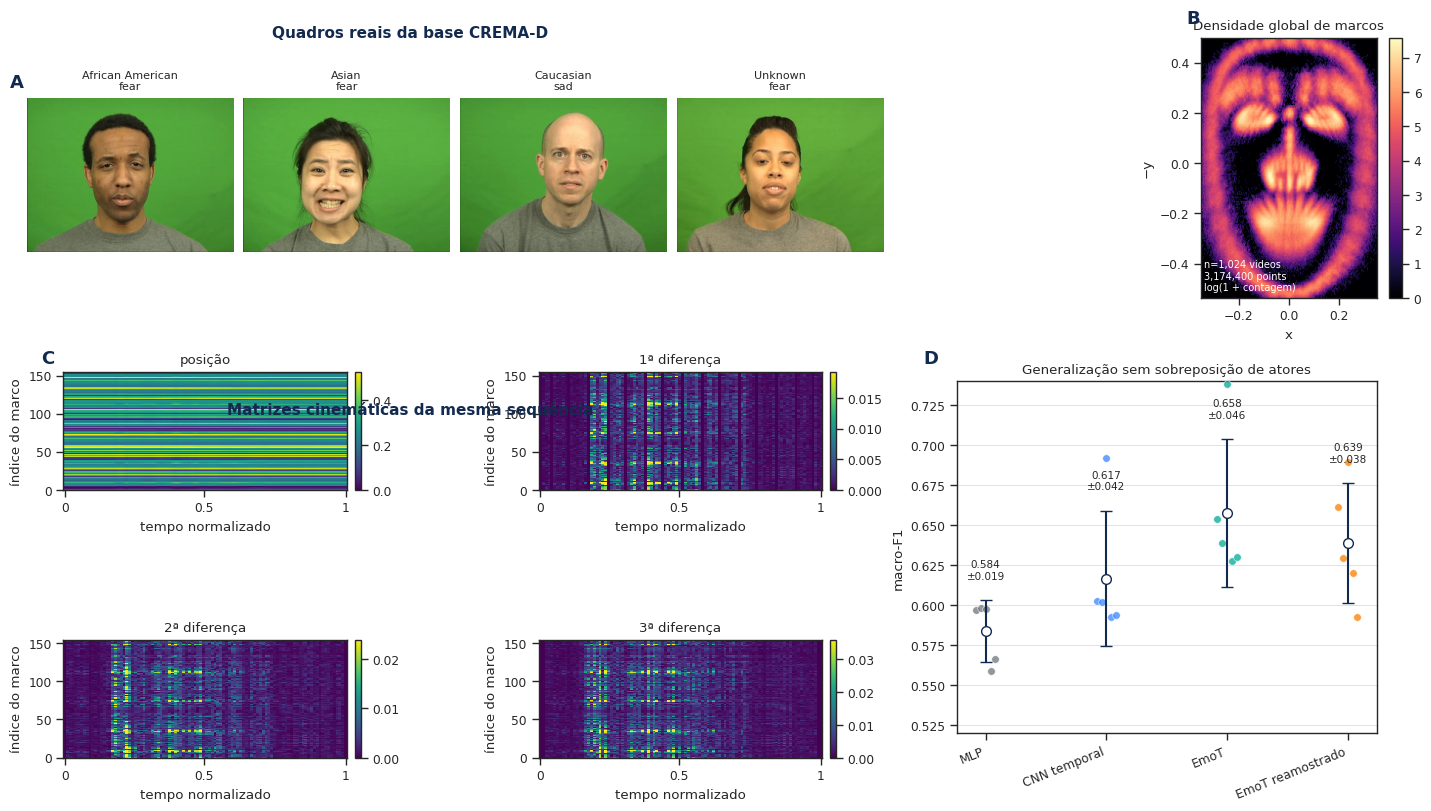

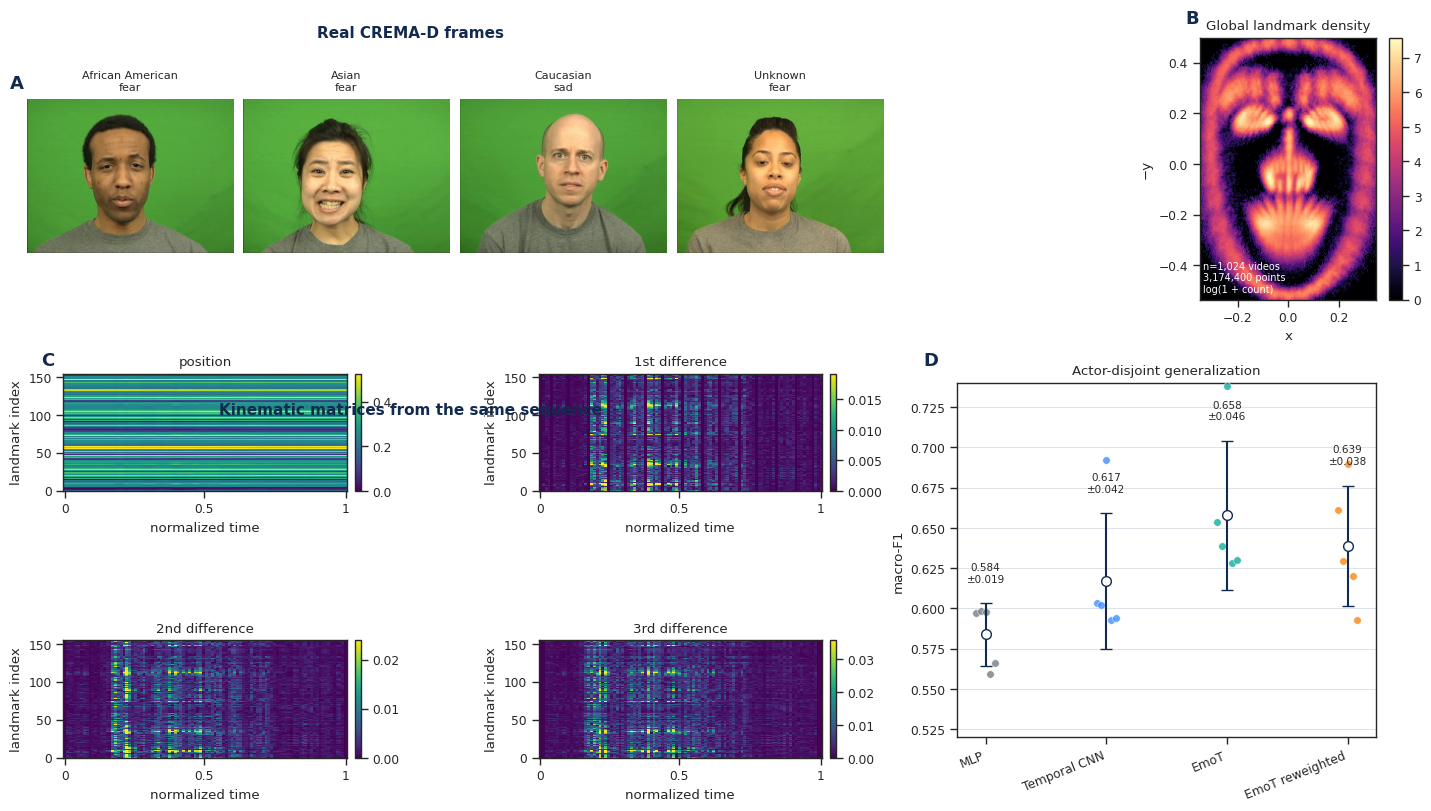

In [6]:
def compute_global_landmark_density(n_videos: int = 1024, temporal_stride: int = 5, bins: int = 180):
    rng = np.random.default_rng(SEED)
    indices = np.sort(rng.choice(len(X_BASE), size=min(n_videos, len(X_BASE)), replace=False))
    coords = X_BASE[indices, ::temporal_stride].reshape(-1, 155, 2).reshape(-1, 2)
    x, y = coords[:, 0], -coords[:, 1]
    xlim = np.quantile(x, [0.001, 0.999])
    ylim = np.quantile(y, [0.001, 0.999])
    density, x_edges, y_edges = np.histogram2d(x, y, bins=bins, range=[xlim, ylim])
    return np.log1p(density.T), x_edges, y_edges, len(indices), len(coords)


DENSITY, DENSITY_X, DENSITY_Y, DENSITY_N_VIDEOS, DENSITY_N_POINTS = compute_global_landmark_density()


TEXT_EXPERIMENTAL = {
    "pt": {
        "frames": "Quadros reais da base CREMA-D",
        "density": "Densidade global de marcos",
        "density_note": "log(1 + contagem)",
        "kinematic": "Matrizes cinemáticas da mesma sequência",
        "time": "tempo normalizado",
        "landmark": "índice do marco",
        "performance": "Generalização sem sobreposição de atores",
        "macro": "macro-F1",
        "models": ["MLP", "CNN temporal", "EmoT", "EmoT reamostrado"],
        "blocks": ["posição", "1ª diferença", "2ª diferença", "3ª diferença"],
    },
    "en": {
        "frames": "Real CREMA-D frames",
        "density": "Global landmark density",
        "density_note": "log(1 + count)",
        "kinematic": "Kinematic matrices from the same sequence",
        "time": "normalized time",
        "landmark": "landmark index",
        "performance": "Actor-disjoint generalization",
        "macro": "macro-F1",
        "models": ["MLP", "Temporal CNN", "EmoT", "EmoT reweighted"],
        "blocks": ["position", "1st difference", "2nd difference", "3rd difference"],
    },
}


def build_experimental_figure(language: str):
    text = TEXT_EXPERIMENTAL[language]
    fig = plt.figure(figsize=(14.2, 8.0), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, width_ratios=[1.05, 1.05, 1.0], height_ratios=[0.85, 1.15])

    frame_grid = gs[0, :2].subgridspec(1, len(EXAMPLES), wspace=0.03)
    for j, row in EXAMPLES.iterrows():
        ax = fig.add_subplot(frame_grid[0, j])
        frame = read_video_frames(str(row["file_stem"]), [0.5])[0]
        ax.imshow(frame)
        race = str(row.get("Race", ""))
        emotion = str(row.get("label_name", ""))
        ax.set_title(f"{race}\n{emotion}", fontsize=8)
        ax.axis("off")
        if j == 0:
            panel_label(ax, "A")
    fig.text(0.285, 0.975, text["frames"], ha="center", va="top", fontsize=11, fontweight="bold", color=PALETTE["navy"])

    ax_density = fig.add_subplot(gs[0, 2])
    extent = [DENSITY_X[0], DENSITY_X[-1], DENSITY_Y[0], DENSITY_Y[-1]]
    im = ax_density.imshow(DENSITY, origin="lower", extent=extent, cmap="magma", aspect="equal")
    ax_density.set_title(text["density"])
    ax_density.set_xlabel("x")
    ax_density.set_ylabel("−y")
    ax_density.text(0.02, 0.02, f"n={DENSITY_N_VIDEOS:,} videos\n{DENSITY_N_POINTS:,} points\n{text['density_note']}", transform=ax_density.transAxes, color="white", fontsize=7, va="bottom")
    panel_label(ax_density, "B")
    fig.colorbar(im, ax=ax_density, fraction=0.045, pad=0.03)

    matrix_grid = gs[1, :2].subgridspec(2, 2, wspace=0.12, hspace=0.22)
    blocks = compute_temporal_blocks(PRIMARY_SEQ)
    for block_index, (block, title) in enumerate(zip(blocks, text["blocks"])):
        ax = fig.add_subplot(matrix_grid[block_index // 2, block_index % 2])
        matrix = block_magnitude(block).T
        _, vmax = robust_limits(matrix)
        img = ax.imshow(matrix, aspect="auto", origin="lower", cmap="viridis", vmin=0, vmax=vmax, interpolation="nearest")
        ax.set_title(title)
        ax.set_xlabel(text["time"])
        ax.set_ylabel(text["landmark"])
        ax.set_xticks([0, 49, 99], ["0", "0.5", "1"])
        if block_index == 0:
            panel_label(ax, "C")
        fig.colorbar(img, ax=ax, fraction=0.035, pad=0.02)
    fig.text(0.285, 0.485, text["kinematic"], ha="center", va="bottom", fontsize=11, fontweight="bold", color=PALETTE["navy"])

    ax_perf = fig.add_subplot(gs[1, 2])
    order = ["FlatMLP", "TemporalCNN1D", "EmoT", "EmoT_Reweighted"]
    colors = ["#6C757D", "#3A86FF", "#00A896", "#F77F00"]
    for i, (model, color) in enumerate(zip(order, colors)):
        values = CV_FOLDS.loc[CV_FOLDS["model"] == model, "macro_f1"].to_numpy(float)
        offsets = np.linspace(-0.08, 0.08, len(values))
        ax_perf.scatter(np.full(len(values), i) + offsets, values, s=30, color=color, alpha=0.75, edgecolor="white", linewidth=0.5, zorder=3)
        mean, std = values.mean(), values.std(ddof=1)
        ax_perf.errorbar(i, mean, yerr=std, fmt="o", color=PALETTE["navy"], mfc="white", ms=7, capsize=4, lw=1.5, zorder=4)
        ax_perf.text(i, mean + std + 0.012, f"{mean:.3f}\n±{std:.3f}", ha="center", va="bottom", fontsize=7.5)
    ax_perf.set_xticks(range(4), text["models"], rotation=22, ha="right")
    ax_perf.set_ylabel(text["macro"])
    ax_perf.set_title(text["performance"])
    ax_perf.grid(axis="y", color="#DDE3EA", linewidth=0.7)
    ax_perf.set_ylim(0.52, 0.74)
    panel_label(ax_perf, "D")
    return fig


if should_run("experimental"):
    for language in ("pt", "en"):
        fig = build_experimental_figure(language)
        save_figure(
            fig,
            "visao_experimental_comparativa_v2.png",
            language,
            "real CREMA-D frames; canonical landmark cache; actual five-fold metrics",
        )
    mark_stage("experimental", {"sample_stems": EXAMPLES["file_stem"].astype(str).tolist(), "density_videos": DENSITY_N_VIDEOS, "density_points": DENSITY_N_POINTS})
else:
    print("[skip] Figura experimental já concluída.")


## Figura 2 — adaptação representacional do EmoT

A figura explicita o que foi substituído e o que foi preservado. Os quadros, trajetórias e matrizes faciais são reais; a descrição da entrada corporal é mantida apenas como referência conceitual ao artigo original do EmoT, sem apresentar dados corporais como se tivessem sido executados neste experimento.


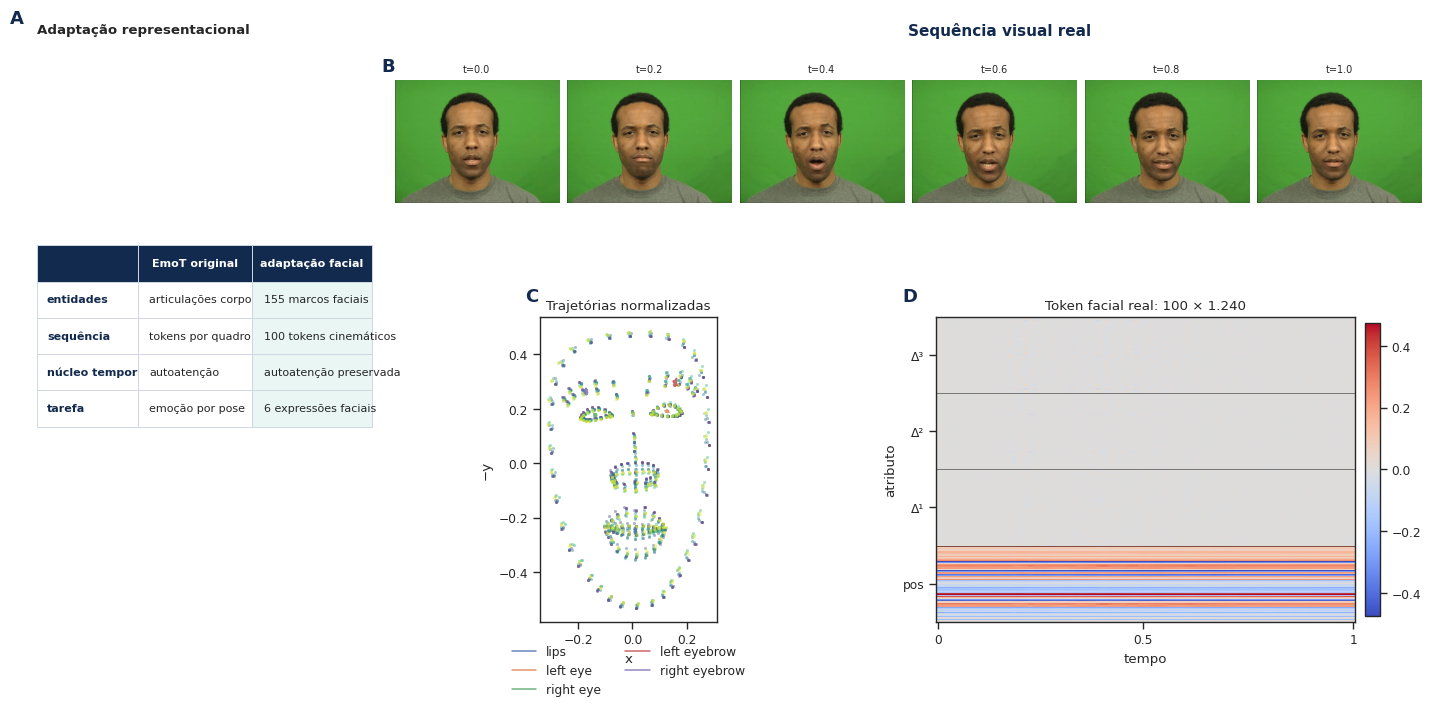

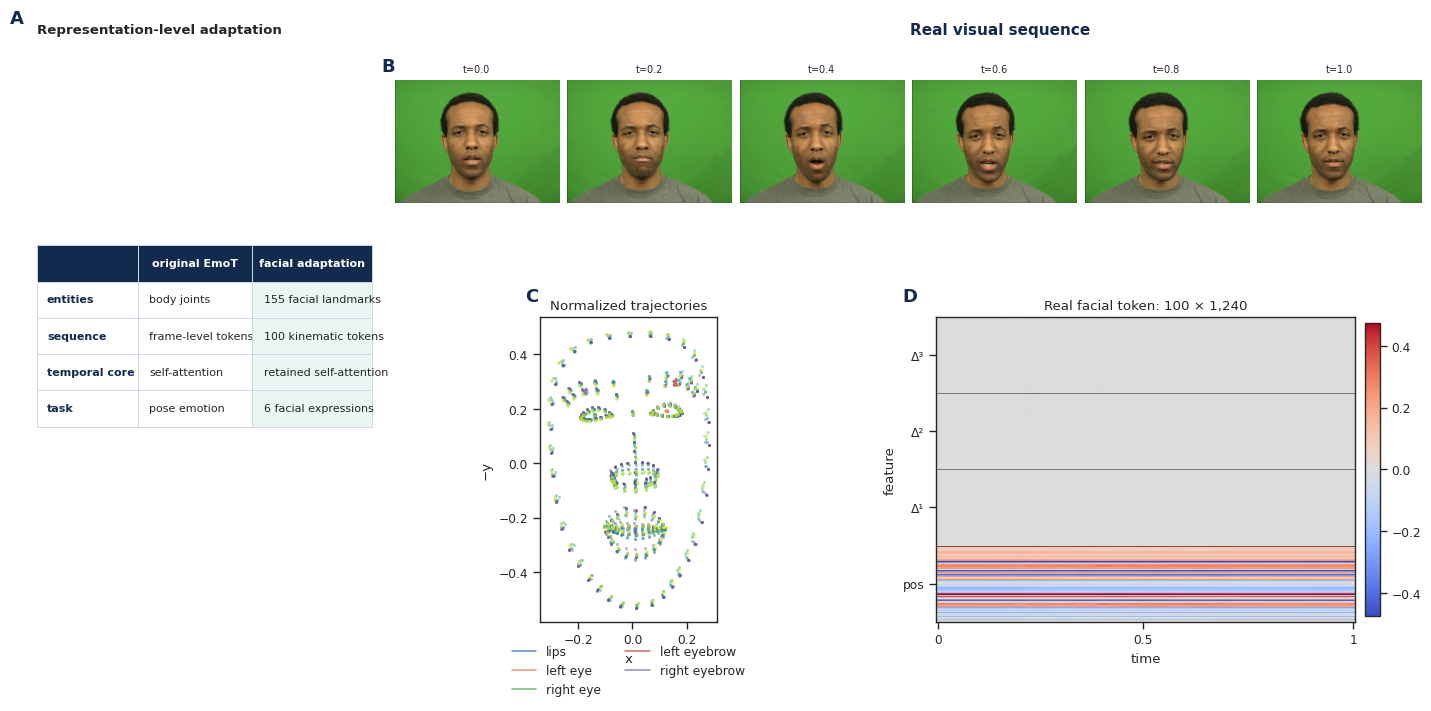

In [7]:
TEXT_ADAPTATION = {
    "pt": {
        "table_title": "Adaptação representacional",
        "rows": ["entidades", "sequência", "núcleo temporal", "tarefa"],
        "source": ["articulações corporais", "tokens por quadro", "autoatenção", "emoção por pose"],
        "target": ["155 marcos faciais", "100 tokens cinemáticos", "autoatenção preservada", "6 expressões faciais"],
        "source_head": "EmoT original",
        "target_head": "adaptação facial",
        "frames": "Sequência visual real",
        "trajectory": "Trajetórias normalizadas",
        "matrix": "Token facial real: 100 × 1.240",
        "time": "tempo",
        "feature": "atributo",
    },
    "en": {
        "table_title": "Representation-level adaptation",
        "rows": ["entities", "sequence", "temporal core", "task"],
        "source": ["body joints", "frame-level tokens", "self-attention", "pose emotion"],
        "target": ["155 facial landmarks", "100 kinematic tokens", "retained self-attention", "6 facial expressions"],
        "source_head": "original EmoT",
        "target_head": "facial adaptation",
        "frames": "Real visual sequence",
        "trajectory": "Normalized trajectories",
        "matrix": "Real facial token: 100 × 1,240",
        "time": "time",
        "feature": "feature",
    },
}


def build_adaptation_figure(language: str):
    text = TEXT_ADAPTATION[language]
    blocks = compute_temporal_blocks(PRIMARY_SEQ)
    token = np.concatenate(blocks, axis=1)
    frames = read_video_frames(PRIMARY_STEM, np.linspace(0, 1, 6).tolist())
    coords = PRIMARY_SEQ.reshape(100, 155, 2)

    fig = plt.figure(figsize=(14.2, 7.0), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, width_ratios=[0.92, 1.35, 1.15], height_ratios=[0.75, 1.0])

    ax_table = fig.add_subplot(gs[:, 0])
    ax_table.axis("off")
    table_data = [[row, src, dst] for row, src, dst in zip(text["rows"], text["source"], text["target"])]
    table = ax_table.table(
        cellText=table_data,
        colLabels=["", text["source_head"], text["target_head"]],
        loc="center",
        cellLoc="left",
        colWidths=[0.30, 0.34, 0.36],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(8)
    table.scale(1.0, 2.05)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("#CFD7E3")
        cell.set_linewidth(0.7)
        if row == 0:
            cell.set_facecolor(PALETTE["navy"])
            cell.set_text_props(color="white", weight="bold")
        elif col == 2:
            cell.set_facecolor("#EAF6F3")
        elif col == 0:
            cell.set_text_props(weight="bold", color=PALETTE["navy"])
    ax_table.set_title(text["table_title"], loc="left", pad=12, fontweight="bold")
    panel_label(ax_table, "A")

    frame_grid = gs[0, 1:].subgridspec(1, 6, wspace=0.02)
    for j, frame in enumerate(frames):
        ax = fig.add_subplot(frame_grid[0, j])
        ax.imshow(frame)
        ax.set_title(f"t={j/5:.1f}", fontsize=7)
        ax.axis("off")
        if j == 0:
            panel_label(ax, "B")
    fig.text(0.70, 0.975, text["frames"], ha="center", va="top", fontsize=11, fontweight="bold", color=PALETTE["navy"])

    ax_traj = fig.add_subplot(gs[1, 1])
    time_indices = np.linspace(0, 99, 10).round().astype(int)
    cmap = mpl.colormaps["viridis"]
    for rank, t in enumerate(time_indices):
        xy = coords[t]
        ax_traj.scatter(xy[:, 0], -xy[:, 1], s=5, alpha=0.42, color=cmap(rank / (len(time_indices) - 1)), linewidth=0)
    for region in ["lips", "left_eye", "right_eye", "left_eyebrow", "right_eyebrow"]:
        positions = REGION_POSITIONS[region]
        centroid = coords[:, positions].mean(axis=1)
        ax_traj.plot(centroid[:, 0], -centroid[:, 1], lw=1.1, alpha=0.85, label=region.replace("_", " "))
    ax_traj.set_aspect("equal", adjustable="box")
    ax_traj.set_title(text["trajectory"])
    ax_traj.set_xlabel("x")
    ax_traj.set_ylabel("−y")
    ax_traj.legend(frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.28))
    panel_label(ax_traj, "C")

    ax_matrix = fig.add_subplot(gs[1, 2])
    vmin, vmax = robust_limits(token, symmetric=True)
    image = ax_matrix.imshow(token.T, aspect="auto", origin="lower", cmap="coolwarm", norm=TwoSlopeNorm(vcenter=0, vmin=vmin, vmax=vmax), interpolation="nearest")
    for boundary in [310, 620, 930]:
        ax_matrix.axhline(boundary - 0.5, color="black", lw=0.5, alpha=0.65)
    ax_matrix.set_yticks([155, 465, 775, 1085], ["pos", "Δ¹", "Δ²", "Δ³"])
    ax_matrix.set_xticks([0, 49, 99], ["0", "0.5", "1"])
    ax_matrix.set_xlabel(text["time"])
    ax_matrix.set_ylabel(text["feature"])
    ax_matrix.set_title(text["matrix"])
    fig.colorbar(image, ax=ax_matrix, fraction=0.035, pad=0.02)
    panel_label(ax_matrix, "D")
    return fig


if should_run("adaptation"):
    for language in ("pt", "en"):
        save_figure(
            build_adaptation_figure(language),
            "adaptacao_emot_corpo_face_v2.png",
            language,
            "real CREMA-D frames and canonical 100x310 landmark sequence; source-domain column is conceptual",
        )
    mark_stage("adaptation", {"primary_sample": PRIMARY_STEM})
else:
    print("[skip] Figura de adaptação já concluída.")


## Figura 3 — arquitetura observada por matrizes internas

O checkpoint do EmoT executado é carregado em modo de avaliação. Para uma sequência real, a figura mostra a entrada padronizada, a projeção de 192 dimensões, as seis matrizes de autoatenção médias entre as três cabeças e as probabilidades finais. Nenhuma matriz é sintetizada.


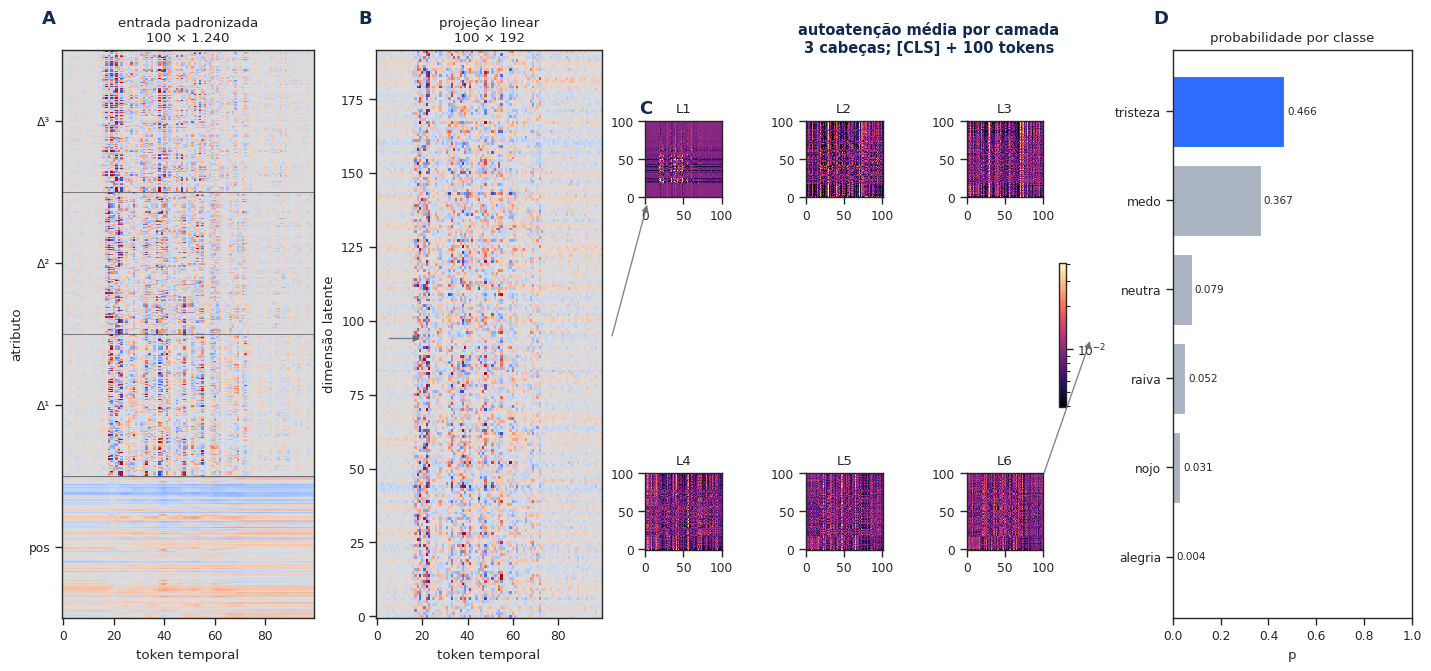

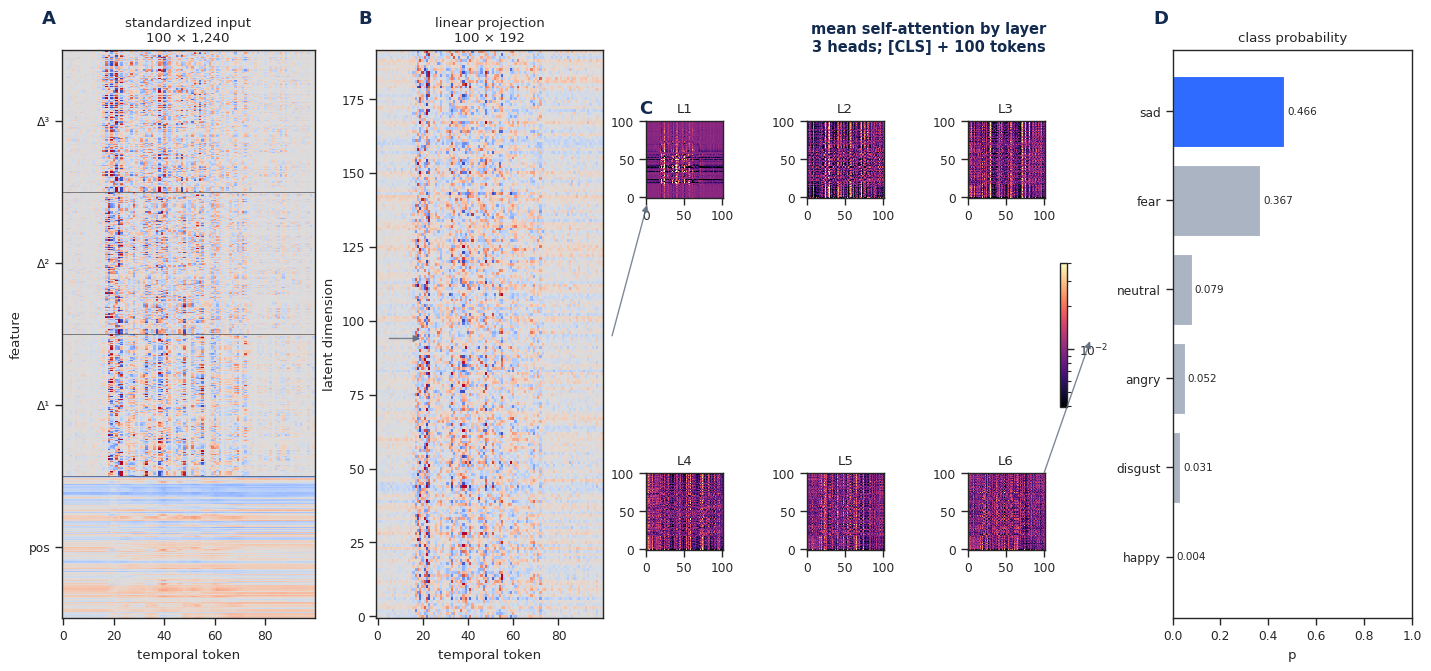

In [8]:
class PedroStyleTransformerBlockWithAttention(nn.Module):
    def __init__(self, d_model, n_heads, dim_ff, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.drop1 = nn.Dropout(dropout)
        self.norm1 = nn.LayerNorm(d_model, eps=1e-6)
        self.ff = nn.Sequential(nn.Linear(d_model, dim_ff), nn.GELU(), nn.Linear(dim_ff, d_model))
        self.drop2 = nn.Dropout(dropout)
        self.norm2 = nn.LayerNorm(d_model, eps=1e-6)

    def forward(self, x, return_attention=False):
        attn_out, attn_w = self.attn(x, x, x, need_weights=return_attention, average_attn_weights=False)
        x = self.norm1(x + self.drop1(attn_out))
        x = self.norm2(x + self.drop2(self.ff(x)))
        return (x, attn_w) if return_attention else (x, None)


class EmoTransformer(nn.Module):
    def __init__(self, D=1240, n_classes=6, d_model=192, n_heads=3, n_layers=6, dim_ff=768, dropout=0.30, mlp_head_size=256, max_len=100):
        super().__init__()
        self.input_proj = nn.Linear(D, d_model)
        self.cls_token = nn.Parameter(torch.empty(1, 1, d_model))
        self.pos_embed = nn.Parameter(torch.empty(1, max_len + 1, d_model))
        self.blocks = nn.ModuleList([PedroStyleTransformerBlockWithAttention(d_model, n_heads, dim_ff, dropout) for _ in range(n_layers)])
        self.head = nn.Sequential(nn.Linear(d_model, mlp_head_size), nn.Linear(mlp_head_size, n_classes))

    def forward(self, x, return_attention=False):
        B = x.size(0)
        projected = self.input_proj(x)
        cls = self.cls_token.expand(B, -1, -1)
        hidden = torch.cat([cls, projected], dim=1)
        hidden = hidden + self.pos_embed[:, : hidden.size(1), :]
        attentions = []
        for block in self.blocks:
            hidden, attn = block(hidden, return_attention=return_attention)
            if return_attention:
                attentions.append(attn)
        logits = self.head(hidden[:, 0])
        return (logits, attentions, projected, hidden) if return_attention else logits


def load_checkpoint(path: Path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


CHECKPOINT = load_checkpoint(LOCAL["checkpoint"])
MODEL = EmoTransformer()
MODEL.load_state_dict(CHECKPOINT["model_state_dict"], strict=True)
MODEL.eval()

PRIMARY_TOKEN = np.concatenate(compute_temporal_blocks(PRIMARY_SEQ), axis=1).astype(np.float32)
MU = np.asarray(CHECKPOINT["mu"], dtype=np.float32)
SIGMA = np.asarray(CHECKPOINT["sigma"], dtype=np.float32)
SIGMA[SIGMA == 0] = 1.0
PRIMARY_STANDARDIZED = (PRIMARY_TOKEN - MU) / SIGMA

with torch.no_grad():
    model_input = torch.from_numpy(PRIMARY_STANDARDIZED[None])
    LOGITS, ATTENTION_LAYERS, PROJECTED, FINAL_HIDDEN = MODEL(model_input, return_attention=True)
    PROBABILITIES = F.softmax(LOGITS, dim=1).cpu().numpy()[0]
    PROJECTED_MATRIX = PROJECTED.cpu().numpy()[0]
    ATTENTION_MATRICES = np.stack([layer.mean(dim=1).cpu().numpy()[0] for layer in ATTENTION_LAYERS])

assert PROJECTED_MATRIX.shape == (100, 192)
assert ATTENTION_MATRICES.shape == (6, 101, 101)


TEXT_ARCH = {
    "pt": {"input": "entrada padronizada\n100 × 1.240", "projection": "projeção linear\n100 × 192", "attention": "autoatenção média por camada\n3 cabeças; [CLS] + 100 tokens", "output": "probabilidade por classe", "time": "token temporal", "feature": "atributo", "hidden": "dimensão latente", "classes": CLASS_NAMES_PT},
    "en": {"input": "standardized input\n100 × 1,240", "projection": "linear projection\n100 × 192", "attention": "mean self-attention by layer\n3 heads; [CLS] + 100 tokens", "output": "class probability", "time": "temporal token", "feature": "feature", "hidden": "latent dimension", "classes": CLASS_NAMES_EN},
}


def build_architecture_figure(language: str):
    text = TEXT_ARCH[language]
    fig = plt.figure(figsize=(14.2, 6.6), constrained_layout=True)
    gs = fig.add_gridspec(1, 4, width_ratios=[0.95, 0.85, 1.9, 0.9])

    ax_input = fig.add_subplot(gs[0, 0])
    low, high = robust_limits(PRIMARY_STANDARDIZED, symmetric=True)
    im_input = ax_input.imshow(PRIMARY_STANDARDIZED.T, aspect="auto", origin="lower", cmap="coolwarm", norm=TwoSlopeNorm(vcenter=0, vmin=low, vmax=high), interpolation="nearest")
    for boundary in [310, 620, 930]:
        ax_input.axhline(boundary - 0.5, color="black", lw=0.45, alpha=0.7)
    ax_input.set_title(text["input"])
    ax_input.set_xlabel(text["time"])
    ax_input.set_ylabel(text["feature"])
    ax_input.set_yticks([155, 465, 775, 1085], ["pos", "Δ¹", "Δ²", "Δ³"])
    panel_label(ax_input, "A")

    ax_projection = fig.add_subplot(gs[0, 1])
    low, high = robust_limits(PROJECTED_MATRIX, symmetric=True)
    ax_projection.imshow(PROJECTED_MATRIX.T, aspect="auto", origin="lower", cmap="coolwarm", norm=TwoSlopeNorm(vcenter=0, vmin=low, vmax=high), interpolation="nearest")
    ax_projection.set_title(text["projection"])
    ax_projection.set_xlabel(text["time"])
    ax_projection.set_ylabel(text["hidden"])
    panel_label(ax_projection, "B")

    attention_grid = gs[0, 2].subgridspec(2, 3, wspace=0.08, hspace=0.16)
    positive = ATTENTION_MATRICES[ATTENTION_MATRICES > 0]
    vmin = max(float(np.quantile(positive, 0.02)), 1e-6)
    vmax = float(np.quantile(positive, 0.998))
    for layer_index in range(6):
        ax = fig.add_subplot(attention_grid[layer_index // 3, layer_index % 3])
        im_attn = ax.imshow(ATTENTION_MATRICES[layer_index], origin="lower", cmap="magma", norm=LogNorm(vmin=vmin, vmax=vmax), interpolation="nearest")
        ax.set_title(f"L{layer_index + 1}")
        ax.set_xticks([0, 50, 100])
        ax.set_yticks([0, 50, 100])
        if layer_index == 0:
            panel_label(ax, "C")
    fig.text(0.65, 0.975, text["attention"], ha="center", va="top", fontsize=10.5, fontweight="bold", color=PALETTE["navy"])
    fig.colorbar(im_attn, ax=[fig.axes[i] for i in range(2, 8)], fraction=0.018, pad=0.01)

    ax_output = fig.add_subplot(gs[0, 3])
    order = np.argsort(PROBABILITIES)
    colors = [PALETTE["blue"] if idx == int(PROBABILITIES.argmax()) else "#AAB4C3" for idx in order]
    ax_output.barh(np.arange(6), PROBABILITIES[order], color=colors)
    ax_output.set_yticks(np.arange(6), [text["classes"][idx] for idx in order])
    ax_output.set_xlabel("p")
    ax_output.set_xlim(0, max(1.0, PROBABILITIES.max() * 1.12))
    ax_output.set_title(text["output"])
    for y_pos, value in enumerate(PROBABILITIES[order]):
        ax_output.text(value + 0.012, y_pos, f"{value:.3f}", va="center", fontsize=7.5)
    panel_label(ax_output, "D")

    # Fluxo visual discreto, sem caixas decorativas.
    for left, right in [(ax_input, ax_projection), (ax_projection, fig.axes[2]), (fig.axes[7], ax_output)]:
        p1, p2 = left.get_position(), right.get_position()
        fig.add_artist(mpl.patches.FancyArrowPatch((p1.x1 + 0.004, (p1.y0 + p1.y1) / 2), (p2.x0 - 0.004, (p2.y0 + p2.y1) / 2), transform=fig.transFigure, arrowstyle="-|>", mutation_scale=10, lw=1.0, color=PALETTE["slate"], alpha=0.8))
    return fig


if should_run("architecture"):
    for language in ("pt", "en"):
        save_figure(
            build_architecture_figure(language),
            "arquitetura_emot_facial_v2.png",
            language,
            "executed checkpoint; real standardized token matrix; real projections, six layer attention matrices, and output probabilities",
        )
    mark_stage("architecture", {"primary_sample": PRIMARY_STEM, "predicted_class": int(PROBABILITIES.argmax()), "probabilities": PROBABILITIES.tolist()})
else:
    print("[skip] Figura de arquitetura já concluída.")


## Figura 4 — Gradientes Integrados e validação XAI

A amostra representativa é escolhida por regra determinística: o vídeo cuja atribuição total está mais próxima da mediana das amostras de Gradientes Integrados. A figura apresenta quadro real, mapa espacial de marcos, matriz espaço-temporal de atribuição, Attention Rollout, matriz de oclusão e concordância com Captum.


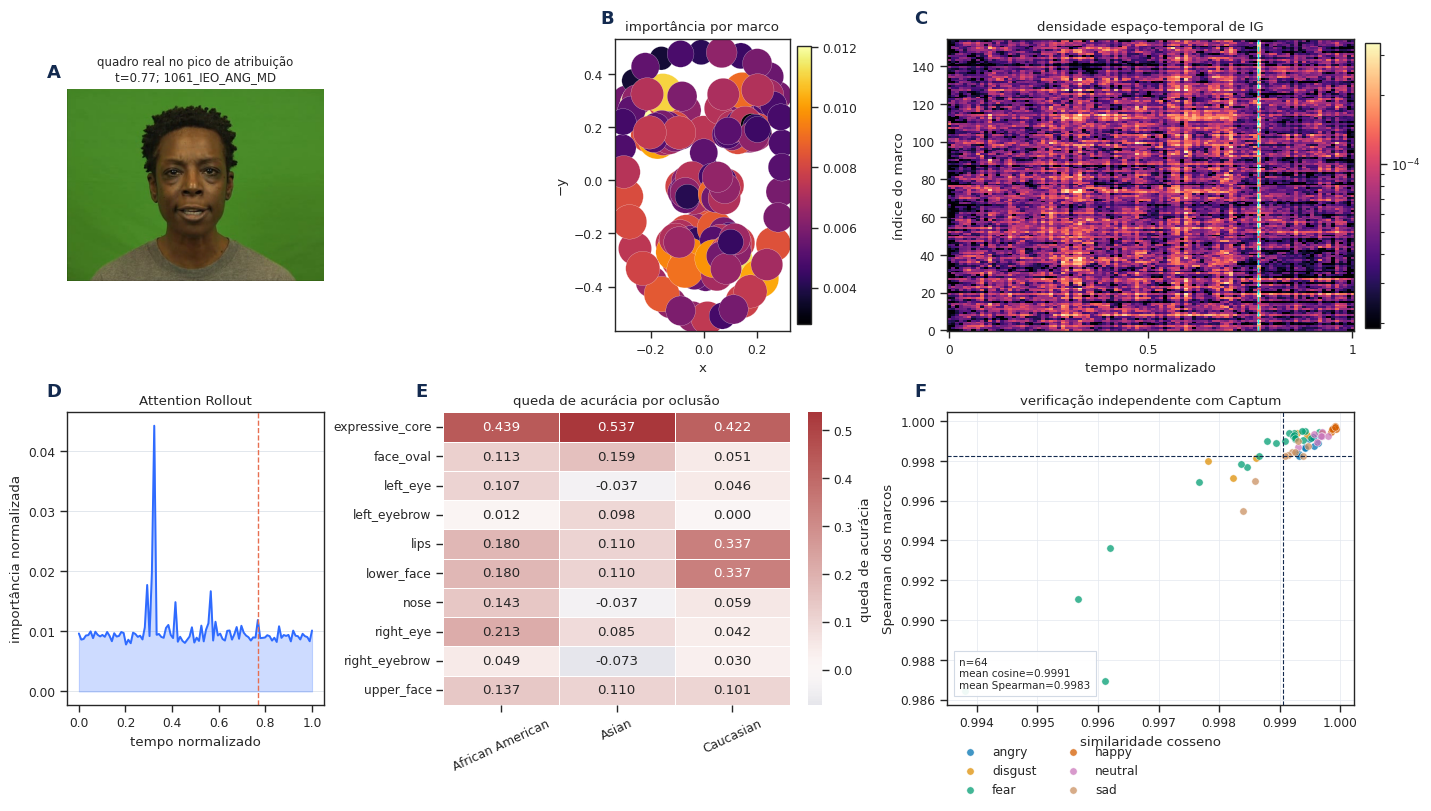

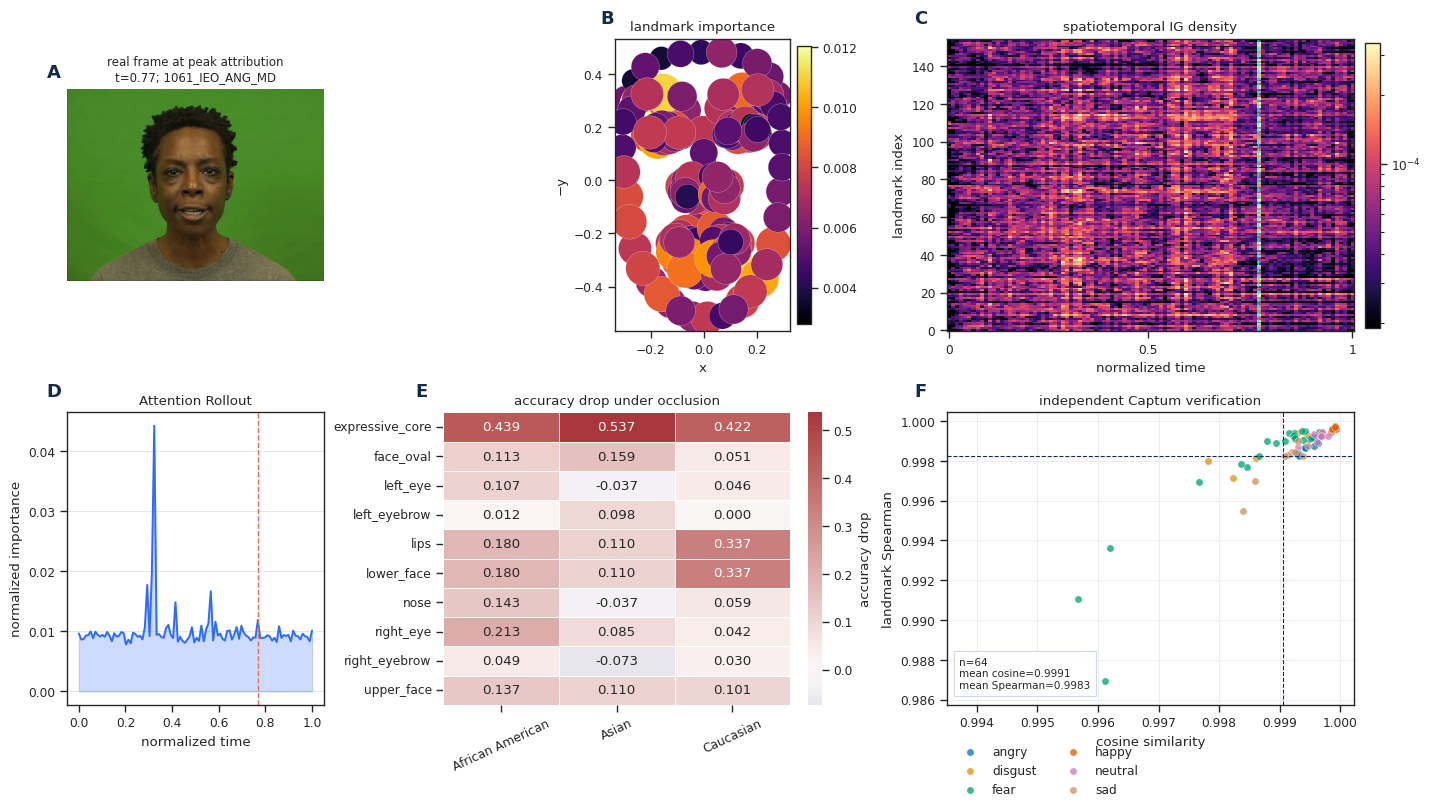

In [9]:
# A representatividade é definida pela massa absoluta de atribuição. Embora o
# experimento tenha persistido |IG|, a expressão permanece correta caso uma
# versão futura do artefato preserve o sinal.
IG_TOTAL = np.abs(IG_ATTR).reshape(len(IG_ATTR), -1).sum(axis=1)
IG_SAMPLE = int(np.argmin(np.abs(IG_TOTAL - np.median(IG_TOTAL))))
XAI_ROW = int(IG_INDICES[IG_SAMPLE])
IG_STEM = str(XAI_MANIFEST.iloc[XAI_ROW]["file_stem"])
IG_BASE_INDEX = STEM_TO_INDEX[IG_STEM]
IG_SEQ = X_BASE[IG_BASE_INDEX]

attr = np.abs(IG_ATTR[IG_SAMPLE]).reshape(100, 4, 155, 2)
IG_TIME_LANDMARK = attr.mean(axis=(1, 3))
IG_TIME_LANDMARK /= max(float(IG_TIME_LANDMARK.sum()), 1e-12)
IG_LANDMARK = IG_TIME_LANDMARK.sum(axis=0)
PEAK_TIME = int(IG_TIME_LANDMARK.sum(axis=1).argmax())
PEAK_FRAME = read_video_frames(IG_STEM, [PEAK_TIME / 99])[0]
IG_COORDS = IG_SEQ[PEAK_TIME].reshape(155, 2)
ATTN_CURVE = ATTENTION_CURVES[XAI_ROW]

TEXT_XAI = {
    "pt": {"frame": "quadro real no pico de atribuição", "spatial": "importância por marco", "heatmap": "densidade espaço-temporal de IG", "attention": "Attention Rollout", "occlusion": "queda de acurácia por oclusão", "captum": "verificação independente com Captum", "time": "tempo normalizado", "landmark": "índice do marco", "importance": "importância normalizada", "acc_drop": "queda de acurácia", "cos": "similaridade cosseno", "spear": "Spearman dos marcos"},
    "en": {"frame": "real frame at peak attribution", "spatial": "landmark importance", "heatmap": "spatiotemporal IG density", "attention": "Attention Rollout", "occlusion": "accuracy drop under occlusion", "captum": "independent Captum verification", "time": "normalized time", "landmark": "landmark index", "importance": "normalized importance", "acc_drop": "accuracy drop", "cos": "cosine similarity", "spear": "landmark Spearman"},
}


def build_xai_figure(language: str):
    text = TEXT_XAI[language]
    fig = plt.figure(figsize=(14.2, 8.0), constrained_layout=True)
    gs = fig.add_gridspec(2, 3, width_ratios=[0.85, 1.15, 1.35], height_ratios=[1.0, 1.0])

    ax_frame = fig.add_subplot(gs[0, 0])
    ax_frame.imshow(PEAK_FRAME)
    ax_frame.set_title(f"{text['frame']}\nt={PEAK_TIME/99:.2f}; {IG_STEM}", fontsize=8.5)
    ax_frame.axis("off")
    panel_label(ax_frame, "A")

    ax_spatial = fig.add_subplot(gs[0, 1])
    sizes = 12 + 900 * IG_LANDMARK / max(float(IG_LANDMARK.max()), 1e-12)
    scatter = ax_spatial.scatter(IG_COORDS[:, 0], -IG_COORDS[:, 1], c=IG_LANDMARK, s=sizes, cmap="inferno", linewidth=0.15, edgecolor="white")
    ax_spatial.set_aspect("equal", adjustable="box")
    ax_spatial.set_xlabel("x")
    ax_spatial.set_ylabel("−y")
    ax_spatial.set_title(text["spatial"])
    fig.colorbar(scatter, ax=ax_spatial, fraction=0.04, pad=0.02)
    panel_label(ax_spatial, "B")

    ax_heat = fig.add_subplot(gs[0, 2])
    positive = IG_TIME_LANDMARK[IG_TIME_LANDMARK > 0]
    vmin = max(float(np.quantile(positive, 0.05)), 1e-10)
    vmax = float(np.quantile(positive, 0.999))
    heat = ax_heat.imshow(IG_TIME_LANDMARK.T, aspect="auto", origin="lower", cmap="magma", norm=LogNorm(vmin=vmin, vmax=vmax), interpolation="nearest")
    ax_heat.axvline(PEAK_TIME, color="cyan", lw=1.0, ls="--", alpha=0.9)
    ax_heat.set_xticks([0, 49, 99], ["0", "0.5", "1"])
    ax_heat.set_xlabel(text["time"])
    ax_heat.set_ylabel(text["landmark"])
    ax_heat.set_title(text["heatmap"])
    fig.colorbar(heat, ax=ax_heat, fraction=0.035, pad=0.02)
    panel_label(ax_heat, "C")

    ax_attn = fig.add_subplot(gs[1, 0])
    time_axis = np.linspace(0, 1, 100)
    ax_attn.fill_between(time_axis, ATTN_CURVE, color=PALETTE["blue"], alpha=0.24)
    ax_attn.plot(time_axis, ATTN_CURVE, color=PALETTE["blue"], lw=1.4)
    ax_attn.axvline(PEAK_TIME / 99, color=PALETTE["orange"], lw=1.0, ls="--")
    ax_attn.set_xlabel(text["time"])
    ax_attn.set_ylabel(text["importance"])
    ax_attn.set_title(text["attention"])
    ax_attn.grid(axis="y", color="#DDE3EA", linewidth=0.6)
    panel_label(ax_attn, "D")

    ax_occ = fig.add_subplot(gs[1, 1])
    occ = OCCLUSION.pivot_table(index="region", columns="Race", values="accuracy_drop", aggfunc="mean")
    sns.heatmap(occ, cmap="vlag", center=0, annot=True, fmt=".3f", linewidths=0.5, linecolor="white", cbar_kws={"label": text["acc_drop"]}, ax=ax_occ)
    ax_occ.set_xlabel("")
    ax_occ.set_ylabel("")
    ax_occ.set_title(text["occlusion"])
    ax_occ.tick_params(axis="x", rotation=25)
    panel_label(ax_occ, "E")

    ax_cap = fig.add_subplot(gs[1, 2])
    x = CAPTUM["cosine_similarity_manual_vs_captum"].to_numpy(float)
    y = CAPTUM["spearman_landmark_rank_manual_vs_captum"].to_numpy(float)
    hue = CAPTUM["target_emotion"].astype(str)
    for emotion, color in zip(sorted(hue.unique()), sns.color_palette("colorblind", n_colors=hue.nunique())):
        mask = hue == emotion
        ax_cap.scatter(x[mask], y[mask], s=28, alpha=0.75, color=color, edgecolor="white", linewidth=0.4, label=emotion)
    ax_cap.axvline(x.mean(), color=PALETTE["navy"], lw=0.8, ls="--")
    ax_cap.axhline(y.mean(), color=PALETTE["navy"], lw=0.8, ls="--")
    ax_cap.text(0.03, 0.05, f"n={len(CAPTUM)}\nmean cosine={x.mean():.4f}\nmean Spearman={y.mean():.4f}", transform=ax_cap.transAxes, fontsize=7.5, va="bottom", bbox={"facecolor": "white", "edgecolor": "#CFD7E3", "alpha": 0.92})
    ax_cap.set_xlabel(text["cos"])
    ax_cap.set_ylabel(text["spear"])
    ax_cap.set_title(text["captum"])
    ax_cap.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, -0.35))
    ax_cap.grid(color="#E3E8EF", linewidth=0.5)
    panel_label(ax_cap, "F")
    return fig


if should_run("xai"):
    for language in ("pt", "en"):
        save_figure(
            build_xai_figure(language),
            "xai_gradientes_integrados_v2.png",
            language,
            "real frame; canonical Integrated Gradients tensor; Attention Rollout; region occlusion; Captum validation",
        )
    mark_stage("xai", {"representative_rule": "closest total IG attribution to cohort median", "ig_sample": IG_SAMPLE, "xai_row": XAI_ROW, "file_stem": IG_STEM, "peak_time_index": PEAK_TIME})
else:
    print("[skip] Figura XAI já concluída.")


## Auditoria, legendas e pacote final

Esta etapa registra hashes das figuras e produz um ZIP pequeno, pronto para inspeção e posterior substituição no Overleaf. O notebook deliberadamente não altera nenhum projeto Overleaf.


In [10]:
# Reconstitui o manifesto inclusive quando algumas etapas foram puladas.
records = []
for language, directory in [("pt", PT_DIR), ("en", EN_DIR)]:
    for path in sorted(directory.glob("*.png")):
        records.append(
            {
                "language": language,
                "file": str(path.relative_to(OUTPUT_ROOT)),
                "bytes": path.stat().st_size,
                "sha256": sha256_file(path),
                "run_id": RUN_ID,
            }
        )

figure_manifest = pd.DataFrame(records)
figure_manifest.to_csv(OUTPUT_ROOT / "figure_manifest.csv", index=False)

captions_pt = '''# Legendas propostas — PT-BR

1. **Desenho experimental.** Quadros reais do CREMA-D, densidade de marcos estimada do cache canônico, matrizes de posição e diferenças temporais da mesma sequência e macro-F1 nas cinco partições externas por ator. Os quatro modelos recebem o mesmo tensor de entrada.
2. **Adaptação representacional do EmoT.** A autoatenção temporal é preservada, enquanto articulações corporais são substituídas por 155 marcos faciais. Os painéis visuais e matriciais derivam de uma sequência real; o domínio corporal é descrito apenas como referência conceitual.
3. **Arquitetura executada.** Matrizes internas produzidas pelo checkpoint canônico para uma sequência real: entrada padronizada, projeção de 192 dimensões, autoatenção média das três cabeças em seis camadas e probabilidades de saída.
4. **Evidência XAI.** Quadro real, atribuição espacial por marco, matriz espaço-temporal de Gradientes Integrados, Attention Rollout, oclusão regional e concordância com Captum. A amostra é escolhida pela proximidade de sua atribuição total à mediana da coorte IG.
'''

captions_en = '''# Proposed captions — English

1. **Experimental design.** Real CREMA-D frames, landmark density estimated from the canonical cache, position and temporal-difference matrices from the same sequence, and macro-F1 across five outer actor-disjoint folds. All four models receive the same input tensor.
2. **Representation-level EmoT adaptation.** Temporal self-attention is retained while body joints are replaced by 155 facial landmarks. Visual and matrix panels derive from a real sequence; the body domain is described only as a conceptual reference.
3. **Executed architecture.** Internal matrices produced by the canonical checkpoint for a real sequence: standardized input, 192-dimensional projection, three-head mean self-attention across six layers, and output probabilities.
4. **XAI evidence.** Real frame, spatial landmark attribution, spatiotemporal Integrated Gradients matrix, Attention Rollout, regional occlusion, and Captum agreement. The sample is selected by proximity of its total attribution to the IG cohort median.
'''

(OUTPUT_ROOT / "CAPTIONS_PTBR.md").write_text(captions_pt, encoding="utf-8")
(OUTPUT_ROOT / "CAPTIONS_EN.md").write_text(captions_en, encoding="utf-8")

readme = f'''# CREMA-D paper figures V3

- Canonical run: `{RUN_ID}`
- Source: `{RUN_DIR}`
- Landmark cache: `{PATHS['landmarks']}`
- Figures are generated from real frames and persisted experiment arrays.
- Overleaf was not modified by this notebook.
- See `input_artifact_audit.csv`, `figure_manifest.csv`, and `state/*.json` for provenance and recovery metadata.
'''
(OUTPUT_ROOT / "README.md").write_text(readme, encoding="utf-8")

# O ZIP fica fora da pasta compactada para nunca incluir a si próprio em uma
# reexecução. O conteúdo continua persistente no mesmo diretório pai do Drive.
zip_base = OUTPUT_ROOT.parent / f"cremad_paper_figures_v3_{RUN_ID}"
zip_path = Path(shutil.make_archive(str(zip_base), "zip", root_dir=OUTPUT_ROOT))

print(f"Pacote final: {zip_path}")
print(f"SHA-256: {sha256_file(zip_path)}")
display(figure_manifest)

if DOWNLOAD_FINAL_ZIP:
    files.download(str(zip_path))


Pacote final: /content/drive/MyDrive/cremad_fairness_xai/paper_figures_v3/cremad_paper_figures_v3_20260809_223452_c0613d3c.zip
SHA-256: 61fc03be1487b24c28e8b7c35f3f62edc865260d93b8466eb73cc9be4c567258


,language,file,bytes,sha256,run_id
0,pt,overleaf_ptbr/figures/adaptacao_emot_corpo_fac...,2159596,73d449acdbfeab1a193494fd5baeac71f746b2923a2a18...,20260809_223452_c0613d3c
1,pt,overleaf_ptbr/figures/arquitetura_emot_facial_...,1310363,ce2a97160f14aa240e4c3cf97f9c2b8e436572d0d16095...,20260809_223452_c0613d3c
2,pt,overleaf_ptbr/figures/visao_experimental_compa...,2343266,ffe3e9cdc7be25b5f1ca940bb1db77444839823ae2938b...,20260809_223452_c0613d3c
3,pt,overleaf_ptbr/figures/xai_gradientes_integrado...,1738846,9a92c271b0a525916969d824dd043d408a33493e0d8793...,20260809_223452_c0613d3c
4,en,overleaf_en/figures/adaptacao_emot_corpo_face_...,2138659,982fa1b1cc97f17ca706cccdc67991b2794565c5b28f23...,20260809_223452_c0613d3c
5,en,overleaf_en/figures/arquitetura_emot_facial_v2...,1298332,4447becaadc5e1b64e83326317c52d79dffe78e0f85c08...,20260809_223452_c0613d3c
6,en,overleaf_en/figures/visao_experimental_compara...,2312600,8a1aced109d66964f0f11c67d1a0fb4ff2124811ed35ca...,20260809_223452_c0613d3c
7,en,overleaf_en/figures/xai_gradientes_integrados_...,1705902,ff58b127e875abae421d47fcb27c170fec370bb0ed4396...,20260809_223452_c0613d3c
